# curl, Requests, XPath, and CSS selectors

Setup

In [1]:
%%capture output
%%bash
apt-get update
apt-get install -y tree telnet netcat-openbsd


In [2]:
import gzip
import pandas as pd
import requests
import io
import json
import bs4
from lxml import html as xhtml


## Resources

- [Introduction to web scraping]( https://carpentries-incubator.github.io/lc-webscraping/ )

  - [Selecting content on a web page with XPath]( https://carpentries-incubator.github.io/lc-webscraping/02-xpath/index.html )

  - [Web scraping using Python and Scrapy]( https://carpentries-incubator.github.io/lc-webscraping/04-scrapy/index.html )

- [Playwright]( https://playwright.dev/python/ )

- [HTML Scraping](https://python-docs.readthedocs.io/en/latest/scenarios/scrape.html)

- [Parsing HTML with Beautiful Soup 4]( https://automatetheboringstuff.com/3e/chapter13.html#:~:text=Parsing%20HTML%20with%20Beautiful%20Soup )

  - [Sample files as zip]( https://nostarch.com/download/Automate_the_Boring_Stuff_onlinematerials_v.2.zip )

- [CSS Selector notation]( https://www.w3schools.com/cssref/css_selectors.php )



## Hyper Text Markup Language ( HTML )



"HTML describes the structure of a web page semantically and originally included cues for its appearance."

Features:
- Text with "markup"
- markup == HTML elements/tags
- most tags paired, <html> ... </html>
- nested: tags within tags forming a hierarchy or tree

The term was coined by [Ted Nelson]( https://en.wikipedia.org/wiki/Ted_Nelson ) around 1963 and implemented by [Tim Berners-Lee]( https://en.wikipedia.org/wiki/Tim_Berners-Lee ) in 1989.

A simple [markup example.]( https://en.wikipedia.org/wiki/HTML#Markup )





## Viewing HTML from the browser



### Example.com



One way:
1. View the webpage at http://www.example.com
1. View the source ( Ctrl+U )

Another way:
1. Open Developer tools ( Ctrl+Shift+I )
1. Click on the Elements tab
1. Alt+click or right+click on the "<html>" tag and select "Expand Recursively"

Locating individual elements:
1. Click on the "Select an Element" arrow ( Ctrl+Shift+C )
1. Click on the text "More information..."

Notice that the corresponding section of HTML is highlighted.  You can also click on a section of HTML and the corresponding element in the page will be highlighted.





### ABQ Library



One way:
1. Visit [ABQ databases]( https://abqlibrary.org/az.php?p=1 )
1. View the source ( Ctrl+U )

Another way:
1. Open Developer tools ( Ctrl+Shift+I )
1. Click on the Elements tab
1. Alt+click or right+click on the "<html>" tag and select "Expand Recursively"



## From the command line





In [3]:
!curl http://www.example.com


<!doctype html><html lang=en><head><meta charset=utf-8><link rel=icon href=data:,><meta name=viewport content="width=device-width,initial-scale=1"><title>Example Domain</title><style>html{color-scheme:light dark;background:light-dark(#eee,#222)}body{font:16px/1.6 system-ui,sans-serif;max-width:26em;margin:auto;padding:25vh 2em 2em;text-align:center}</style></head><body><p>This domain is for use in documentation examples without needing permission. This is not a service; avoid relying on it for testing and monitoring purposes.</p><script src=/s.js></script></body></html>


In [4]:
!curl -s -v https://abqlibrary.org/az.php?p=1 2>&1 | cat -n

     1	* Host abqlibrary.org:443 was resolved.
     2	* IPv6: (none)
     3	* IPv4: 34.194.39.199
     4	*   Trying 34.194.39.199:443...
     5	* Connected to abqlibrary.org (34.194.39.199) port 443
     6	* ALPN: curl offers h2,http/1.1
     7	} [5 bytes data]
     8	* TLSv1.3 (OUT), TLS handshake, Client hello (1):
     9	} [512 bytes data]
    10	*  CAfile: /etc/ssl/certs/ca-certificates.crt
    11	*  CApath: /etc/ssl/certs
    12	{ [5 bytes data]
    13	* TLSv1.3 (IN), TLS handshake, Server hello (2):
    14	{ [122 bytes data]
    15	* TLSv1.3 (IN), TLS handshake, Encrypted Extensions (8):
    16	{ [19 bytes data]
    17	* TLSv1.3 (IN), TLS handshake, Certificate (11):
    18	{ [3416 bytes data]
    19	* TLSv1.3 (IN), TLS handshake, CERT verify (15):
    20	{ [80 bytes data]
    21	* TLSv1.3 (IN), TLS handshake, Finished (20):
    22	{ [52 bytes data]
    23	* TLSv1.3 (OUT), TLS change cipher, Change cipher spec (1):
    24	} [1 bytes data]
    25	* TLSv1.3 (OUT), TLS handshake, Fi

In [5]:
!curl -s -v https://abqlibrary.org/az/databases 2>&1 | cat -n

     1	* Host abqlibrary.org:443 was resolved.
     2	* IPv6: (none)
     3	* IPv4: 34.194.39.199
     4	*   Trying 34.194.39.199:443...
     5	* Connected to abqlibrary.org (34.194.39.199) port 443
     6	* ALPN: curl offers h2,http/1.1
     7	} [5 bytes data]
     8	* TLSv1.3 (OUT), TLS handshake, Client hello (1):
     9	} [512 bytes data]
    10	*  CAfile: /etc/ssl/certs/ca-certificates.crt
    11	*  CApath: /etc/ssl/certs
    12	{ [5 bytes data]
    13	* TLSv1.3 (IN), TLS handshake, Server hello (2):
    14	{ [122 bytes data]
    15	* TLSv1.3 (IN), TLS handshake, Encrypted Extensions (8):
    16	{ [19 bytes data]
    17	* TLSv1.3 (IN), TLS handshake, Certificate (11):
    18	{ [3416 bytes data]
    19	* TLSv1.3 (IN), TLS handshake, CERT verify (15):
    20	{ [79 bytes data]
    21	* TLSv1.3 (IN), TLS handshake, Finished (20):
    22	{ [52 bytes data]
    23	* TLSv1.3 (OUT), TLS change cipher, Change cipher spec (1):
    24	} [1 bytes data]
    25	* TLSv1.3 (OUT), TLS handshake, Fi

In [6]:
!curl -s -v -L https://abqlibrary.org/az.php?p=1 2>&1 | cat -n

     1	* Host abqlibrary.org:443 was resolved.
     2	* IPv6: (none)
     3	* IPv4: 34.194.39.199
     4	*   Trying 34.194.39.199:443...
     5	* Connected to abqlibrary.org (34.194.39.199) port 443
     6	* ALPN: curl offers h2,http/1.1
     7	} [5 bytes data]
     8	* TLSv1.3 (OUT), TLS handshake, Client hello (1):
     9	} [512 bytes data]
    10	*  CAfile: /etc/ssl/certs/ca-certificates.crt
    11	*  CApath: /etc/ssl/certs
    12	{ [5 bytes data]
    13	* TLSv1.3 (IN), TLS handshake, Server hello (2):
    14	{ [122 bytes data]
    15	* TLSv1.3 (IN), TLS handshake, Encrypted Extensions (8):
    16	{ [19 bytes data]
    17	* TLSv1.3 (IN), TLS handshake, Certificate (11):
    18	{ [3416 bytes data]
    19	* TLSv1.3 (IN), TLS handshake, CERT verify (15):
    20	{ [79 bytes data]
    21	* TLSv1.3 (IN), TLS handshake, Finished (20):
    22	{ [52 bytes data]
    23	* TLSv1.3 (OUT), TLS change cipher, Change cipher spec (1):
    24	} [1 bytes data]
    25	* TLSv1.3 (OUT), TLS handshake, Fi

## Hyper Text Transfer Protocol ( HTTP )



From [Wikipedia: HTTP]( https://en.wikipedia.org/wiki/HTTP )

"The Hypertext Transfer Protocol (HTTP) is an application layer protocol in the Internet protocol suite model for distributed, collaborative, hypermedia information systems."

"In 1991, the first documented official version of HTTP ..., HTTP/0.9, supported only GET method, allowing clients to only retrieve HTML documents from the server, but not supporting any other file formats or information upload."

Features:
- Data flows as a Request/Response pair
- Connections are "stateless", i.e. the server doesn't remember previous requests/responses.
- Requests contain a "verb" and key:value pairs in a Header, and sometimes a payload.
- Responses contain a "status" and key:value pairs in a Header, and often a payload.




Although the protocol has a number of methods/verbs, we will be primarily using GET, HEAD, and POST methods.
- [HTTP methods]( https://en.wikipedia.org/wiki/HTTP#Request_methods )

### Sequence Diagrams of HTTP

- [HTTP sequence diagrams]( https://gist.github.com/rwcitek/397849af2eb90d59e9b6f67d89065a24 )

### Viewing request/response pair from the browser


1. View the webpage at http://www.example.com
1. Open Developer tools ( Ctrl+Shift+I )
1. Click on the Network tab
1. Refresh the page
1. Under the Name field, click on "www.example.com"
1. Scroll down to see the General, Request, and Response sections.
1. Click on the Raw checkbox.
1. Click on the Response tab to view the response payload.







### Viewing request/response pair with curl


Requests have a "> " at the beginning of the line.

Responses have a "< " at the beginning of the line.

In [7]:
!curl --help


Usage: curl [options...] <url>
 -d, --data <data>          HTTP POST data
 -f, --fail                 Fail fast with no output on HTTP errors
 -h, --help <category>      Get help for commands
 -i, --include              Include protocol response headers in the output
 -o, --output <file>        Write to file instead of stdout
 -O, --remote-name          Write output to a file named as the remote file
 -s, --silent               Silent mode
 -T, --upload-file <file>   Transfer local FILE to destination
 -u, --user <user:password> Server user and password
 -A, --user-agent <name>    Send User-Agent <name> to server
 -v, --verbose              Make the operation more talkative
 -V, --version              Show version number and quit

This is not the full help, this menu is stripped into categories.
Use "--help category" to get an overview of all categories.
For all options use the manual or "--help all".


In [8]:
!curl -s -v http://www.example.com 2>&1 | cat -n

     1	* Host www.example.com:80 was resolved.
     2	* IPv6: 2606:4700:10::6814:179a, 2606:4700:10::ac42:93f3
     3	* IPv4: 104.20.23.154, 172.66.147.243
     4	*   Trying 104.20.23.154:80...
     5	* Connected to www.example.com (104.20.23.154) port 80
     6	> GET / HTTP/1.1
     7	> Host: www.example.com
     8	> User-Agent: curl/8.5.0
     9	> Accept: */*
    10	> 
    11	< HTTP/1.1 200 OK
    12	< Date: Thu, 12 Nov 2026 20:14:25 GMT
    13	< Content-Type: text/html; charset=utf-8
    14	< Transfer-Encoding: chunked
    15	< Connection: keep-alive
    16	< Server: cloudflare
    17	< Last-Modified: Sun, 08 Nov 2026 18:05:34 GMT
    18	< Allow: GET, HEAD
    19	< Accept-Ranges: bytes
    20	< Age: 9257
    21	< cf-cache-status: HIT
    22	< CF-RAY: a59833f1a843869a-ATL
    23	< alt-svc: h3=":443"; ma=86400
    24	< 
    25	{ [577 bytes data]
    26	* Connection #0 to host www.example.com left intact
    27	<!doctype html><html lang=en><head><meta charset=utf-8><link rel=icon href=

### Request using telnet



In [9]:
%%bash
telnet www.example.com 80

Trying 104.20.23.154...
Connected to www.example.com.
Escape character is '^]'.


Connection closed by foreign host.


```text
GET / HTTP/1.1
Host: www.example.com
User-Agent: telnet
Accept: */*
```




### Request using netcat


In [10]:
%%bash

nc example.com 80 << 'EOF'
GET / HTTP/1.1
Host: example.com
User-Agent: netcat
Connection: close

EOF


HTTP/1.1 200 OK
Date: Thu, 12 Nov 2026 20:14:25 GMT
Content-Type: text/html; charset=utf-8
Transfer-Encoding: chunked
Connection: close
Server: cloudflare
Last-Modified: Sun, 08 Nov 2026 18:05:34 GMT
Allow: GET, HEAD
Accept-Ranges: bytes
Age: 7
cf-cache-status: HIT
CF-RAY: a59833f29e32b469-ATL
alt-svc: h3=":443"; ma=86400

241
<!doctype html><html lang=en><head><meta charset=utf-8><link rel=icon href=data:,><meta name=viewport content="width=device-width,initial-scale=1"><title>Example Domain</title><style>html{color-scheme:light dark;background:light-dark(#eee,#222)}body{font:16px/1.6 system-ui,sans-serif;max-width:26em;margin:auto;padding:25vh 2em 2em;text-align:center}</style></head><body><p>This domain is for use in documentation examples without needing permission. This is not a service; avoid relying on it for testing and monitoring purposes.</p><script src=/s.js></script></body></html>

0



### Request using socat


In [11]:
%%bash

socat stdio,ignoreeof tcp:example.com:80 << 'EOF'
GET / HTTP/1.1
Host: www.example.com
User-Agent: socat
Connection: close

EOF


HTTP/1.1 200 OK
Date: Thu, 12 Nov 2026 20:14:25 GMT
Content-Type: text/html; charset=utf-8
Transfer-Encoding: chunked
Connection: close
Server: cloudflare
Last-Modified: Sun, 08 Nov 2026 18:05:34 GMT
Allow: GET, HEAD
Accept-Ranges: bytes
Age: 9257
cf-cache-status: HIT
CF-RAY: a59833f2ef56454b-ATL
alt-svc: h3=":443"; ma=86400

241
<!doctype html><html lang=en><head><meta charset=utf-8><link rel=icon href=data:,><meta name=viewport content="width=device-width,initial-scale=1"><title>Example Domain</title><style>html{color-scheme:light dark;background:light-dark(#eee,#222)}body{font:16px/1.6 system-ui,sans-serif;max-width:26em;margin:auto;padding:25vh 2em 2em;text-align:center}</style></head><body><p>This domain is for use in documentation examples without needing permission. This is not a service; avoid relying on it for testing and monitoring purposes.</p><script src=/s.js></script></body></html>

0



### Request using raw tcp


In [12]:
%%bash

exec 3<>/dev/tcp/example.com/80

cat <<EOF >&3
GET / HTTP/1.1
Host: example.com
Connection: close

EOF

cat <&3
exec 3>&-


HTTP/1.1 200 OK
Date: Thu, 12 Nov 2026 20:14:25 GMT
Content-Type: text/html; charset=utf-8
Transfer-Encoding: chunked
Connection: close
Server: cloudflare
Last-Modified: Sun, 08 Nov 2026 18:05:34 GMT
Allow: GET, HEAD
Accept-Ranges: bytes
Age: 9
cf-cache-status: HIT
CF-RAY: a59833f34ce6bfbf-ATL
alt-svc: h3=":443"; ma=86400

241
<!doctype html><html lang=en><head><meta charset=utf-8><link rel=icon href=data:,><meta name=viewport content="width=device-width,initial-scale=1"><title>Example Domain</title><style>html{color-scheme:light dark;background:light-dark(#eee,#222)}body{font:16px/1.6 system-ui,sans-serif;max-width:26em;margin:auto;padding:25vh 2em 2em;text-align:center}</style></head><body><p>This domain is for use in documentation examples without needing permission. This is not a service; avoid relying on it for testing and monitoring purposes.</p><script src=/s.js></script></body></html>

0



## Using Python

### Fetching files/pages using the requests module

In [13]:
page = requests.get('http://www.example.com')


In [14]:
dict(page.headers)


{'Date': 'Thu, 12 Nov 2026 20:14:25 GMT',
 'Content-Type': 'text/html; charset=utf-8',
 'Transfer-Encoding': 'chunked',
 'Connection': 'keep-alive',
 'Server': 'cloudflare',
 'Last-Modified': 'Sun, 08 Nov 2026 18:05:34 GMT',
 'Allow': 'GET, HEAD',
 'cf-cache-status': 'HIT',
 'Age': '9257',
 'Content-Encoding': 'br',
 'CF-RAY': 'a59833f3ac79312e-ATL',
 'alt-svc': 'h3=":443"; ma=86400'}

In [15]:
page.status_code, page.reason


(200, 'OK')

In [16]:
[
page.request.url,
page.request.method,
page.request.path_url,
page.request.headers,
page.request.body,
]

['http://www.example.com/',
 'GET',
 '/',
 {'User-Agent': 'python-requests/2.32.4', 'Accept-Encoding': 'gzip, deflate, br, zstd', 'Accept': '*/*', 'Connection': 'keep-alive'},
 None]

In [17]:
page.url


'http://www.example.com/'

In [18]:
page.connection


In [19]:
page.cookies


<RequestsCookieJar[]>

In [20]:
page.text


'<!doctype html><html lang=en><head><meta charset=utf-8><link rel=icon href=data:,><meta name=viewport content="width=device-width,initial-scale=1"><title>Example Domain</title><style>html{color-scheme:light dark;background:light-dark(#eee,#222)}body{font:16px/1.6 system-ui,sans-serif;max-width:26em;margin:auto;padding:25vh 2em 2em;text-align:center}</style></head><body><p>This domain is for use in documentation examples without needing permission. This is not a service; avoid relying on it for testing and monitoring purposes.</p><script src=/s.js></script></body></html>\n'

In [21]:
page.content


b'<!doctype html><html lang=en><head><meta charset=utf-8><link rel=icon href=data:,><meta name=viewport content="width=device-width,initial-scale=1"><title>Example Domain</title><style>html{color-scheme:light dark;background:light-dark(#eee,#222)}body{font:16px/1.6 system-ui,sans-serif;max-width:26em;margin:auto;padding:25vh 2em 2em;text-align:center}</style></head><body><p>This domain is for use in documentation examples without needing permission. This is not a service; avoid relying on it for testing and monitoring purposes.</p><script src=/s.js></script></body></html>\n'

In [22]:
type(page)

requests.models.Response

In [23]:
ls -la

total 16
drwxr-xr-x 1 root root 4096 Nov 11 15:59 ./
drwxr-xr-x 1 root root 4096 Nov 12 19:42 ../
drwxr-xr-x 4 root root 4096 Nov 11 15:59 .config/
drwxr-xr-x 1 root root 4096 Nov 11 15:59 sample_data/


## Trees


From [Wikipedia: Tree (Graph)]( https://en.wikipedia.org/wiki/Tree_(graph_theory) )

"In graph theory, a tree is an undirected graph in which any two vertices are connected by exactly one path, or equivalently a connected acyclic undirected graph."



![Tree]( https://miro.medium.com/v2/resize:fit:714/1*fZn1qW-gXqQImkNuN1_aUg.png "tree image" )



Structure:
- Type of graph, i.e. nodes and edges
- Zero or one parent node
- Zero or more children nodes

Nomenclature:
- Nodes
- Edges
- Directed edge
- Levels, up, down
- Parent, child, sibling
- Ancestors, descendants
- Root ( no parent )
- Branches ( parents and children )
- Leaves ( no children )
- Path: sequence of nodes and edges between two nodes
- Traversing, recursing; depth first, breadth first

Type of trees:
- Binary: at most two children
- Balanced: equal number of levels for all children

Examples:
- Filesystem
- Org charts
- Family pedigrees
- HTML, XML, JSON, YAML

Example: `tree` command for viewing the filesystem

In [24]:
!tree /etc/apt

/etc/apt
├── apt.conf.d
│   ├── 01autoremove
│   ├── 01-vendor-ubuntu
│   ├── 20packagekit
│   ├── 70debconf
│   ├── 90assumeyes
│   ├── docker-autoremove-suggests
│   ├── docker-clean
│   ├── docker-disable-periodic-update
│   ├── docker-gzip-indexes
│   └── docker-no-languages
├── auth.conf.d
├── keyrings
│   └── githubcli-archive-keyring.gpg
├── preferences.d
├── sources.list
├── sources.list.d
│   ├── archive_uri-https_cloud_r-project_org_bin_linux_ubuntu-noble.list
│   ├── archive_uri-https_r2u_stat_illinois_edu_ubuntu-noble.list
│   ├── deadsnakes-ubuntu-ppa-noble.sources
│   ├── github-cli.list
│   └── ubuntu.sources
└── trusted.gpg.d
    ├── cran_ubuntu_key.asc
    ├── r2u_key.asc
    ├── ubuntu-keyring-2012-cdimage.gpg
    └── ubuntu-keyring-2018-archive.gpg

7 directories, 21 files


In [25]:
!find /etc/apt

/etc/apt
/etc/apt/trusted.gpg.d
/etc/apt/trusted.gpg.d/ubuntu-keyring-2012-cdimage.gpg
/etc/apt/trusted.gpg.d/ubuntu-keyring-2018-archive.gpg
/etc/apt/trusted.gpg.d/cran_ubuntu_key.asc
/etc/apt/trusted.gpg.d/r2u_key.asc
/etc/apt/apt.conf.d
/etc/apt/apt.conf.d/docker-autoremove-suggests
/etc/apt/apt.conf.d/70debconf
/etc/apt/apt.conf.d/docker-no-languages
/etc/apt/apt.conf.d/docker-clean
/etc/apt/apt.conf.d/01autoremove
/etc/apt/apt.conf.d/docker-gzip-indexes
/etc/apt/apt.conf.d/docker-disable-periodic-update
/etc/apt/apt.conf.d/01-vendor-ubuntu
/etc/apt/apt.conf.d/90assumeyes
/etc/apt/apt.conf.d/20packagekit
/etc/apt/auth.conf.d
/etc/apt/preferences.d
/etc/apt/sources.list
/etc/apt/keyrings
/etc/apt/keyrings/githubcli-archive-keyring.gpg
/etc/apt/sources.list.d
/etc/apt/sources.list.d/ubuntu.sources
/etc/apt/sources.list.d/github-cli.list
/etc/apt/sources.list.d/archive_uri-https_r2u_stat_illinois_edu_ubuntu-noble.list
/etc/apt/sources.list.d/deadsnakes-ubuntu-ppa-noble.sources
/etc/ap

## Beautiful Soup and CSS selectors


In [26]:
%%capture
%%bash
curl -s -L -o example.html https://autbor.com/example3.html


In [27]:
pwd

'/content'

In [28]:
ls -l

total 8
-rw-r--r-- 1 root root  957 Nov 12 20:40 example.html
drwxr-xr-x 1 root root 4096 Nov 11 15:59 sample_data/


In [29]:
!cat -n example.html

     1	<!-- This is an HTML comment. -->
     2	
     3	<html>
     4	<head>
     5	    <title>Example Website Title</title>
     6	    <style>
     7	        .slogan {
     8	            color: gray;
     9	            font-size: 2em;
    10	        }
    11	    </style>
    12	</head>
    13	<body>
    14	    <h1>Example Website</h1>
    15	    <p>This &lt;p&gt; tag puts <b>content</b> into a <i>single</i> paragraph.</p>
    16	    <p><a href="https://inventwithpython.com">This text is a link</a> to books by <span id="author">Al Sweigart</span>.</p>
    17	    <p><img src="wow_such_zophie_thumb.webp" alt="Close up of my cat Zophie." /></p>
    18	    <p class="slogan">Learn to program in Python!</p>
    19	    <form>
    20	        <p><label>Username: <input id="login_user" placeholder="admin" /></label></p>
    21	        <p><label>Password: <input id="login_pass" type="password" placeholder="swordfish" /></label></p>
    22	        <p><label>Agree to disagree: <input type="checkbox

In [30]:
with open('example.html') as exampleFile:
  html = exampleFile.read()

exampleSoup = bs4.BeautifulSoup( html, 'html.parser')
print(html)


<!-- This is an HTML comment. -->

<html>
<head>
    <title>Example Website Title</title>
    <style>
        .slogan {
            color: gray;
            font-size: 2em;
        }
    </style>
</head>
<body>
    <h1>Example Website</h1>
    <p>This &lt;p&gt; tag puts <b>content</b> into a <i>single</i> paragraph.</p>
    <p><a href="https://inventwithpython.com">This text is a link</a> to books by <span id="author">Al Sweigart</span>.</p>
    <p><img src="wow_such_zophie_thumb.webp" alt="Close up of my cat Zophie." /></p>
    <p class="slogan">Learn to program in Python!</p>
    <form>
        <p><label>Username: <input id="login_user" placeholder="admin" /></label></p>
        <p><label>Password: <input id="login_pass" type="password" placeholder="swordfish" /></label></p>
        <p><label>Agree to disagree: <input type="checkbox" /></label><input type="submit" value="Fake Button" /></p>
    </form>
</body>
</html>


In [31]:
html

'<!-- This is an HTML comment. -->\n\n<html>\n<head>\n    <title>Example Website Title</title>\n    <style>\n        .slogan {\n            color: gray;\n            font-size: 2em;\n        }\n    </style>\n</head>\n<body>\n    <h1>Example Website</h1>\n    <p>This &lt;p&gt; tag puts <b>content</b> into a <i>single</i> paragraph.</p>\n    <p><a href="https://inventwithpython.com">This text is a link</a> to books by <span id="author">Al Sweigart</span>.</p>\n    <p><img src="wow_such_zophie_thumb.webp" alt="Close up of my cat Zophie." /></p>\n    <p class="slogan">Learn to program in Python!</p>\n    <form>\n        <p><label>Username: <input id="login_user" placeholder="admin" /></label></p>\n        <p><label>Password: <input id="login_pass" type="password" placeholder="swordfish" /></label></p>\n        <p><label>Agree to disagree: <input type="checkbox" /></label><input type="submit" value="Fake Button" /></p>\n    </form>\n</body>\n</html>'

In [32]:
type(html)

str

In [33]:
html[:10]

'<!-- This '

In [34]:
for i, line in enumerate(html.split('\n')):
  print(i+1, line)

1 <!-- This is an HTML comment. -->
2 
3 <html>
4 <head>
5     <title>Example Website Title</title>
6     <style>
7         .slogan {
8             color: gray;
9             font-size: 2em;
10         }
11     </style>
12 </head>
13 <body>
14     <h1>Example Website</h1>
15     <p>This &lt;p&gt; tag puts <b>content</b> into a <i>single</i> paragraph.</p>
16     <p><a href="https://inventwithpython.com">This text is a link</a> to books by <span id="author">Al Sweigart</span>.</p>
17     <p><img src="wow_such_zophie_thumb.webp" alt="Close up of my cat Zophie." /></p>
18     <p class="slogan">Learn to program in Python!</p>
19     <form>
20         <p><label>Username: <input id="login_user" placeholder="admin" /></label></p>
21         <p><label>Password: <input id="login_pass" type="password" placeholder="swordfish" /></label></p>
22         <p><label>Agree to disagree: <input type="checkbox" /></label><input type="submit" value="Fake Button" /></p>
23     </form>
24 </body>
25 </html>


In [35]:
type(exampleSoup)

bs4.BeautifulSoup

In [36]:
elems = exampleSoup.select('#author')
elems

[<span id="author">Al Sweigart</span>]

In [37]:
exampleSoup.select('#login_user')

[<input id="login_user" placeholder="admin"/>]

In [38]:
type(elems) # elems is a list of Tag objects.

bs4.element.ResultSet

In [39]:
len(elems)

1

In [40]:
elems[0]

<span id="author">Al Sweigart</span>

In [41]:
type(elems[0])

bs4.element.Tag

In [42]:
str(elems[0]) # The Tag object as a string.

'<span id="author">Al Sweigart</span>'

In [43]:
elems[0].getText()

'Al Sweigart'

In [44]:
elems[0].attrs

{'id': 'author'}

In [45]:
pElems = exampleSoup.select('p')
pElems

[<p>This &lt;p&gt; tag puts <b>content</b> into a <i>single</i> paragraph.</p>,
 <p><a href="https://inventwithpython.com">This text is a link</a> to books by <span id="author">Al Sweigart</span>.</p>,
 <p><img alt="Close up of my cat Zophie." src="wow_such_zophie_thumb.webp"/></p>,
 <p class="slogan">Learn to program in Python!</p>,
 <p><label>Username: <input id="login_user" placeholder="admin"/></label></p>,
 <p><label>Password: <input id="login_pass" placeholder="swordfish" type="password"/></label></p>,
 <p><label>Agree to disagree: <input type="checkbox"/></label><input type="submit" value="Fake Button"/></p>]

In [46]:
len(pElems)

7

In [47]:
pElems[:2]

[<p>This &lt;p&gt; tag puts <b>content</b> into a <i>single</i> paragraph.</p>,
 <p><a href="https://inventwithpython.com">This text is a link</a> to books by <span id="author">Al Sweigart</span>.</p>]

In [48]:
pElems[0]

<p>This &lt;p&gt; tag puts <b>content</b> into a <i>single</i> paragraph.</p>

In [49]:
type(pElems[0])

bs4.element.Tag

In [50]:
str(pElems[0])

'<p>This &lt;p&gt; tag puts <b>content</b> into a <i>single</i> paragraph.</p>'

In [51]:
pElems[0].getText()

'This <p> tag puts content into a single paragraph.'

In [52]:
str(pElems[1])

'<p><a href="https://inventwithpython.com">This text is a link</a> to books by <span id="author">Al Sweigart</span>.</p>'

In [53]:
pElems[1].getText()

'This text is a link to books by Al Sweigart.'

In [54]:
str(pElems[2])

'<p><img alt="Close up of my cat Zophie." src="wow_such_zophie_thumb.webp"/></p>'

In [55]:
pElems[2].getText()

''

In [56]:
aElems = exampleSoup.select('a')
aElems


[<a href="https://inventwithpython.com">This text is a link</a>]

In [57]:
len(aElems)

1

In [58]:
aElems[0]


<a href="https://inventwithpython.com">This text is a link</a>

In [60]:
aElems[0].getText()

'This text is a link'

In [59]:
aElems[0].attrs


{'href': 'https://inventwithpython.com'}

In [61]:
aElems[0].attrs["href"]


'https://inventwithpython.com'

In [62]:
body_text = exampleSoup.select("body")[0].get_text()
print( body_text )



Example Website
This <p> tag puts content into a single paragraph.
This text is a link to books by Al Sweigart.

Learn to program in Python!

Username: 
Password: 
Agree to disagree: 




In [63]:
body_text

'\nExample Website\nThis <p> tag puts content into a single paragraph.\nThis text is a link to books by Al Sweigart.\n\nLearn to program in Python!\n\nUsername: \nPassword: \nAgree to disagree: \n\n'

In [64]:
body_text.split('\n')


['',
 'Example Website',
 'This <p> tag puts content into a single paragraph.',
 'This text is a link to books by Al Sweigart.',
 '',
 'Learn to program in Python!',
 '',
 'Username: ',
 'Password: ',
 'Agree to disagree: ',
 '',
 '']

### Using the data set from stamp prices


In [65]:
url = 'https://vincentarelbundock.github.io/Rdatasets/datasets.html'
url


'https://vincentarelbundock.github.io/Rdatasets/datasets.html'

In [66]:
datasets_tables = pd.read_html( url )
len(datasets_tables)


2

In [67]:
datasets_df = datasets_tables[1]
datasets_df.head()


,Package,Item,Title,Rows,Cols,n_binary,n_character,n_factor,n_logical,n_numeric,CSV,Doc
0,admiral,admiral_adlb,Lab Analysis Dataset,330,115,13,79,0,0,25,CSV,DOC
1,admiral,admiral_adsl,Subject Level Analysis Dataset,306,54,5,39,0,0,5,CSV,DOC
2,admiral,atoxgr_criteria_ctcv4,Metadata Holding Grading Criteria for NCI-CTCA...,42,13,2,13,0,0,0,CSV,DOC
3,admiral,atoxgr_criteria_ctcv4_uscv,Metadata Holding Grading Criteria for NCI-CTCA...,48,13,2,13,0,0,0,CSV,DOC
4,admiral,atoxgr_criteria_ctcv5,Metadata Holding Grading Criteria for NCI-CTCA...,40,13,2,13,0,0,0,CSV,DOC


In [68]:
datasets_df.shape


(3648, 12)

In [69]:
datasets_df.head()["CSV"]

,CSV
0,CSV
1,CSV
2,CSV
3,CSV
4,CSV


In [70]:
data_sets = requests.get( url )
data_sets


<Response [200]>

In [71]:
html = data_sets.text
html[:1000]


'\n<style type="text/css">\n  tr:nth-child(even){\n          background-color: #E5E7E5;\n  }\n</style>\n\n\n<p align= center >\n<table cellspacing=0 border=1>\n<caption align=bottom class=captiondataframe></caption>\n<tr><td>\n\t<table border=0 class=dataframe>\n\t<tbody> \n\t<tr class= firstline > \n\t\t<th>Package  </th>\n\t\t<th>Item  </th>\n\t\t<th>Title  </th>\n\t\t<th>Rows  </th>\n\t\t<th>Cols  </th>\n\t\t<th>n_binary  </th>\n\t\t<th>n_character  </th>\n\t\t<th>n_factor  </th>\n\t\t<th>n_logical  </th>\n\t\t<th>n_numeric  </th>\n\t\t<th>CSV  </th>\n\t\t<th>Doc</th> \n\t</tr> \n<tr> \n<td class=cellinside>admiral\n</td>\n<td class=cellinside>admiral_adlb\n</td>\n<td class=cellinside>Lab Analysis Dataset\n</td>\n<td class=cellinside>    330\n</td>\n<td class=cellinside> 115\n</td>\n<td class=cellinside>  13\n</td>\n<td class=cellinside>79\n</td>\n<td class=cellinside> 0\n</td>\n<td class=cellinside> 0\n</td>\n<td class=cellinside>  25\n</td>\n<td class=cellinside><a href=\'https://

In [72]:
dom = bs4.BeautifulSoup(html, "html.parser")
str(dom).split("\n")[:10]

['',
 '<style type="text/css">',
 '  tr:nth-child(even){',
 '          background-color: #E5E7E5;',
 '  }',
 '</style>',
 '<p align="center">',
 '<table border="1" cellspacing="0">',
 '<caption align="bottom" class="captiondataframe"></caption>',
 '<tr><td>']

In [73]:
str(dom).split("\n")[:51]


['',
 '<style type="text/css">',
 '  tr:nth-child(even){',
 '          background-color: #E5E7E5;',
 '  }',
 '</style>',
 '<p align="center">',
 '<table border="1" cellspacing="0">',
 '<caption align="bottom" class="captiondataframe"></caption>',
 '<tr><td>',
 '<table border="0" class="dataframe">',
 '<tbody>',
 '<tr class="firstline">',
 '<th>Package  </th>',
 '<th>Item  </th>',
 '<th>Title  </th>',
 '<th>Rows  </th>',
 '<th>Cols  </th>',
 '<th>n_binary  </th>',
 '<th>n_character  </th>',
 '<th>n_factor  </th>',
 '<th>n_logical  </th>',
 '<th>n_numeric  </th>',
 '<th>CSV  </th>',
 '<th>Doc</th>',
 '</tr>',
 '<tr>',
 '<td class="cellinside">admiral',
 '</td>',
 '<td class="cellinside">admiral_adlb',
 '</td>',
 '<td class="cellinside">Lab Analysis Dataset',
 '</td>',
 '<td class="cellinside">    330',
 '</td>',
 '<td class="cellinside"> 115',
 '</td>',
 '<td class="cellinside">  13',
 '</td>',
 '<td class="cellinside">79',
 '</td>',
 '<td class="cellinside"> 0',
 '</td>',
 '<td class="c

In [74]:
a_tags = dom.select("a")
a_tags[:6], a_tags[-6:]



([<a href="https://vincentarelbundock.github.io/Rdatasets/csv/admiral/admiral_adlb.csv"> CSV </a>,
  <a href="https://vincentarelbundock.github.io/Rdatasets/doc/admiral/admiral_adlb.html"> DOC </a>,
  <a href="https://vincentarelbundock.github.io/Rdatasets/csv/admiral/admiral_adsl.csv"> CSV </a>,
  <a href="https://vincentarelbundock.github.io/Rdatasets/doc/admiral/admiral_adsl.html"> DOC </a>,
  <a href="https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_ctcv4.csv"> CSV </a>,
  <a href="https://vincentarelbundock.github.io/Rdatasets/doc/admiral/atoxgr_criteria_ctcv4.html"> DOC </a>],
 [<a href="https://vincentarelbundock.github.io/Rdatasets/csv/wooldridge/wagepan.csv"> CSV </a>,
  <a href="https://vincentarelbundock.github.io/Rdatasets/doc/wooldridge/wagepan.html"> DOC </a>,
  <a href="https://vincentarelbundock.github.io/Rdatasets/csv/wooldridge/wageprc.csv"> CSV </a>,
  <a href="https://vincentarelbundock.github.io/Rdatasets/doc/wooldridge/wageprc.html"> DOC 

In [75]:
len(a_tags)


7296

In [76]:
a_tags[100].attrs.get("href","")

'https://vincentarelbundock.github.io/Rdatasets/csv/AER/GermanUnemployment.csv'

In [77]:
hrefs = [ tag.attrs.get("href","") for tag in a_tags ]
hrefs[:10]


['https://vincentarelbundock.github.io/Rdatasets/csv/admiral/admiral_adlb.csv',
 'https://vincentarelbundock.github.io/Rdatasets/doc/admiral/admiral_adlb.html',
 'https://vincentarelbundock.github.io/Rdatasets/csv/admiral/admiral_adsl.csv',
 'https://vincentarelbundock.github.io/Rdatasets/doc/admiral/admiral_adsl.html',
 'https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_ctcv4.csv',
 'https://vincentarelbundock.github.io/Rdatasets/doc/admiral/atoxgr_criteria_ctcv4.html',
 'https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_ctcv4_uscv.csv',
 'https://vincentarelbundock.github.io/Rdatasets/doc/admiral/atoxgr_criteria_ctcv4_uscv.html',
 'https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_ctcv5.csv',
 'https://vincentarelbundock.github.io/Rdatasets/doc/admiral/atoxgr_criteria_ctcv5.html']

In [78]:
csvs = []
for x in hrefs:
  if x.endswith("csv"):
    csvs.append(x)

len(csvs)


3648

In [79]:
csvs = [ x for x in hrefs if x.endswith("csv") ]
len(csvs)


3648

In [80]:
csvs[:10]

['https://vincentarelbundock.github.io/Rdatasets/csv/admiral/admiral_adlb.csv',
 'https://vincentarelbundock.github.io/Rdatasets/csv/admiral/admiral_adsl.csv',
 'https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_ctcv4.csv',
 'https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_ctcv4_uscv.csv',
 'https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_ctcv5.csv',
 'https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_ctcv5_uscv.csv',
 'https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_ctcv6.csv',
 'https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_ctcv6_uscv.csv',
 'https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_daids.csv',
 'https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_daids_uscv.csv']

In [81]:
for csv in csvs[:10]:
  print(f"== {csv}")
  df = pd.read_csv( csv )
  print(df.index.size)


== https://vincentarelbundock.github.io/Rdatasets/csv/admiral/admiral_adlb.csv
330
== https://vincentarelbundock.github.io/Rdatasets/csv/admiral/admiral_adsl.csv
306
== https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_ctcv4.csv
42
== https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_ctcv4_uscv.csv
48
== https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_ctcv5.csv
40
== https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_ctcv5_uscv.csv
46
== https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_ctcv6.csv
43
== https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_ctcv6_uscv.csv
48
== https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_daids.csv
63
== https://vincentarelbundock.github.io/Rdatasets/csv/admiral/atoxgr_criteria_daids_uscv.csv
71


In [82]:
datasets_df["cvs_url"] = csvs
datasets_df

,Package,Item,Title,Rows,Cols,n_binary,n_character,n_factor,n_logical,n_numeric,CSV,Doc,cvs_url
0,admiral,admiral_adlb,Lab Analysis Dataset,330,115,13,79,0,0,25,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...
1,admiral,admiral_adsl,Subject Level Analysis Dataset,306,54,5,39,0,0,5,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...
2,admiral,atoxgr_criteria_ctcv4,Metadata Holding Grading Criteria for NCI-CTCA...,42,13,2,13,0,0,0,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...
3,admiral,atoxgr_criteria_ctcv4_uscv,Metadata Holding Grading Criteria for NCI-CTCA...,48,13,2,13,0,0,0,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...
4,admiral,atoxgr_criteria_ctcv5,Metadata Holding Grading Criteria for NCI-CTCA...,40,13,2,13,0,0,0,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3643,wooldridge,wage1,wage1,526,24,16,0,0,0,24,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...
3644,wooldridge,wage2,wage2,935,17,4,0,0,0,17,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...
3645,wooldridge,wagepan,wagepan,4360,44,37,0,0,0,44,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...
3646,wooldridge,wageprc,wageprc,286,20,0,0,0,0,20,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...


In [83]:
pd.read_csv(csvs[1]).index.size


306

In [87]:
# datasets_df["row_count"] = [ pd.read_csv(x).index.size for x in csvs ]
# datasets_df


If we get an error, e.g. 503, how should/could we handle it.


In [85]:
docs = [
  x
    for x in hrefs
      if x.endswith("html")
]

len(docs)


3648

In [86]:
datasets_df["docs_url"] = docs
datasets_df

,Package,Item,Title,Rows,Cols,n_binary,n_character,n_factor,n_logical,n_numeric,CSV,Doc,cvs_url,docs_url
0,admiral,admiral_adlb,Lab Analysis Dataset,330,115,13,79,0,0,25,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...,https://vincentarelbundock.github.io/Rdatasets...
1,admiral,admiral_adsl,Subject Level Analysis Dataset,306,54,5,39,0,0,5,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...,https://vincentarelbundock.github.io/Rdatasets...
2,admiral,atoxgr_criteria_ctcv4,Metadata Holding Grading Criteria for NCI-CTCA...,42,13,2,13,0,0,0,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...,https://vincentarelbundock.github.io/Rdatasets...
3,admiral,atoxgr_criteria_ctcv4_uscv,Metadata Holding Grading Criteria for NCI-CTCA...,48,13,2,13,0,0,0,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...,https://vincentarelbundock.github.io/Rdatasets...
4,admiral,atoxgr_criteria_ctcv5,Metadata Holding Grading Criteria for NCI-CTCA...,40,13,2,13,0,0,0,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...,https://vincentarelbundock.github.io/Rdatasets...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3643,wooldridge,wage1,wage1,526,24,16,0,0,0,24,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...,https://vincentarelbundock.github.io/Rdatasets...
3644,wooldridge,wage2,wage2,935,17,4,0,0,0,17,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...,https://vincentarelbundock.github.io/Rdatasets...
3645,wooldridge,wagepan,wagepan,4360,44,37,0,0,0,44,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...,https://vincentarelbundock.github.io/Rdatasets...
3646,wooldridge,wageprc,wageprc,286,20,0,0,0,0,20,CSV,DOC,https://vincentarelbundock.github.io/Rdatasets...,https://vincentarelbundock.github.io/Rdatasets...


### Using DBpedia

In [88]:
dbpedia = requests.get("https://dbpedia.org/page/Digby_Morrell")
dbpedia

<Response [200]>

In [89]:
html = dbpedia.text
html

'<!DOCTYPE html>\n<html\n    prefix="\n        dbp: http://dbpedia.org/property/\n        dbo: http://dbedia.org/ontology/\n        dct: http://purl.org/dc/terms/\n        dbd: http://dbpedia.org/datatype/\n\tog:  https://ogp.me/ns#\n\t"\n>\n\n\n<!-- header -->\n<head>\n    <meta charset="utf-8" />\n    <meta name="viewport" content="width=device-width, initial-scale=1" />\n\n    <title>About: Digby Morrell</title>\n\n    <!-- Links -->\n    <link rel="alternate" type="application/rdf+xml" \t\thref="http://dbpedia.org/data/Digby_Morrell.rdf" title="Structured Descriptor Document (RDF/XML format)" />\n    <link rel="alternate" type="text/n3" \t\t\thref="http://dbpedia.org/data/Digby_Morrell.n3" title="Structured Descriptor Document (N3 format)" />\n    <link rel="alternate" type="text/turtle" \t\t\thref="http://dbpedia.org/data/Digby_Morrell.ttl" title="Structured Descriptor Document (Turtle format)" />\n    <link rel="alternate" type="application/json+rdf" \t\thref="http://dbpedia.org/

In [90]:
dom = bs4.BeautifulSoup(html, "html.parser")
dom

<!DOCTYPE html>

<html prefix="
        dbp: http://dbpedia.org/property/
        dbo: http://dbedia.org/ontology/
        dct: http://purl.org/dc/terms/
        dbd: http://dbpedia.org/datatype/
	og:  https://ogp.me/ns#
	">
<!-- header -->
<head>
<meta charset="utf-8"/>
<meta content="width=device-width, initial-scale=1" name="viewport"/>
<title>About: Digby Morrell</title>
<!-- Links -->
<link href="http://dbpedia.org/data/Digby_Morrell.rdf" rel="alternate" title="Structured Descriptor Document (RDF/XML format)" type="application/rdf+xml"/>
<link href="http://dbpedia.org/data/Digby_Morrell.n3" rel="alternate" title="Structured Descriptor Document (N3 format)" type="text/n3"/>
<link href="http://dbpedia.org/data/Digby_Morrell.ttl" rel="alternate" title="Structured Descriptor Document (Turtle format)" type="text/turtle"/>
<link href="http://dbpedia.org/data/Digby_Morrell.jrdf" rel="alternate" title="Structured Descriptor Document (RDF/JSON format)" type="application/json+rdf"/>
<link h

In [91]:
type(html)

str

In [92]:
type(dom)

bs4.BeautifulSoup

In [93]:
a_tags = dom.select("a")
a_tags

[<a class="navbar-brand" href="http://wiki.dbpedia.org/Imprint" style="color: #2c5078" title="About DBpedia">
 <img alt="About DBpedia" class="img-fluid" src="/statics/images/dbpedia_logo_land_120.png"/>
 </a>,
 <a aria-expanded="false" class="nav-link dropdown-toggle" data-bs-toggle="dropdown" href="#" id="navbarDropdownBrowse" role="button">
 <i class="bi-eye-fill"></i> Browse using<span class="caret"></span></a>,
 <a class="nav-link" href="/describe/?uri=http%3A%2F%2Fdbpedia.org%2Fresource%2FDigby_Morrell">OpenLink Faceted Browser</a>,
 <a class="nav-link" href="http://osde.demo.openlinksw.com/#/editor?uri=http%3A%2F%2Fdbpedia.org%2Fdata%2FDigby_Morrell.ttl&amp;view=statements">OpenLink Structured Data Editor</a>,
 <a class="nav-link" href="http://en.lodlive.it/?http%3A%2F%2Fdbpedia.org%2Fresource%2FDigby_Morrell">LodLive Browser</a>,
 <a aria-expanded="false" class="nav-link dropdown-toggle" data-bs-toggle="dropdown" href="#" id="navbarDropdownFormats" role="button">
 <i class="bi-

In [94]:
len(a_tags)

164

In [95]:
[ tag.attrs for tag in a_tags ]

[{'class': ['navbar-brand'],
  'href': 'http://wiki.dbpedia.org/Imprint',
  'title': 'About DBpedia',
  'style': 'color: #2c5078'},
 {'class': ['nav-link', 'dropdown-toggle'],
  'href': '#',
  'id': 'navbarDropdownBrowse',
  'role': 'button',
  'data-bs-toggle': 'dropdown',
  'aria-expanded': 'false'},
 {'class': ['nav-link'],
  'href': '/describe/?uri=http%3A%2F%2Fdbpedia.org%2Fresource%2FDigby_Morrell'},
 {'class': ['nav-link'],
  'href': 'http://osde.demo.openlinksw.com/#/editor?uri=http%3A%2F%2Fdbpedia.org%2Fdata%2FDigby_Morrell.ttl&view=statements'},
 {'class': ['nav-link'],
  'href': 'http://en.lodlive.it/?http%3A%2F%2Fdbpedia.org%2Fresource%2FDigby_Morrell'},
 {'class': ['nav-link', 'dropdown-toggle'],
  'href': '#',
  'id': 'navbarDropdownFormats',
  'role': 'button',
  'data-bs-toggle': 'dropdown',
  'aria-expanded': 'false'},
 {'class': ['dropdown-item'],
  'href': 'http://dbpedia.org/data/Digby_Morrell.ntriples'},
 {'class': ['dropdown-item'],
  'href': 'http://dbpedia.org/d

In [96]:
for a_tag in a_tags:
  href = a_tag.attrs["href"]
  if href.startswith("http"):
    rev = a_tag.attrs.get("rev","")
    if "foaf:primaryTopic" in rev:
      print(href)


http://en.wikipedia.org/wiki/Digby_Morrell


#### Using only CSS selectors.

In [97]:
foaf_pt = dom.select('a[href^="http"][rev="foaf:primaryTopic"]')
foaf_pt[0].attrs["href"]


'http://en.wikipedia.org/wiki/Digby_Morrell'

In [98]:
foaf_pt[0].attrs["href"].split("/")[-1]


'Digby_Morrell'

### link extraction from web page



- [gist for extracting links from a web page]( https://gist.github.com/rwcitek/6a24241fcc61c0fc4055dda77d347c4a )




Example: extracting all the URLs for data from IMDB.

- [IMDB data]( https://datasets.imdbws.com/ )

In [99]:
url = "https://datasets.imdbws.com/"
soup = bs4.BeautifulSoup(requests.get(url).text, 'html.parser')

imdb_files = [
  tag.get('href')
    for tag in soup.select('a[href$=".tsv.gz"]')
]

imdb_files

['https://datasets.imdbws.com/name.basics.tsv.gz',
 'https://datasets.imdbws.com/title.akas.tsv.gz',
 'https://datasets.imdbws.com/title.basics.tsv.gz',
 'https://datasets.imdbws.com/title.crew.tsv.gz',
 'https://datasets.imdbws.com/title.episode.tsv.gz',
 'https://datasets.imdbws.com/title.principals.tsv.gz',
 'https://datasets.imdbws.com/title.ratings.tsv.gz']

## XPath

Using the `lxml` library to pull the same information as the CSS selector.

In [100]:
page = requests.get('https://autbor.com/example3.html')
tree = xhtml.fromstring(page.content)
tree

<Element html at 0x7e7968ec1a90>

/html/body/p[2]/a

/html/body/p[2] (what I get -- tan 2026-11-12)

In [101]:
page.content

b'<!-- This is an HTML comment. -->\r\n\r\n<html>\r\n<head>\r\n    <title>Example Website Title</title>\r\n    <style>\r\n        .slogan {\r\n            color: gray;\r\n            font-size: 2em;\r\n        }\r\n    </style>\r\n</head>\r\n<body>\r\n    <h1>Example Website</h1>\r\n    <p>This &lt;p&gt; tag puts <b>content</b> into a <i>single</i> paragraph.</p>\r\n    <p><a href="https://inventwithpython.com">This text is a link</a> to books by <span id="author">Al Sweigart</span>.</p>\r\n    <p><img src="wow_such_zophie_thumb.webp" alt="Close up of my cat Zophie." /></p>\r\n    <p class="slogan">Learn to program in Python!</p>\r\n    <form>\r\n        <p><label>Username: <input id="login_user" placeholder="admin" /></label></p>\r\n        <p><label>Password: <input id="login_pass" type="password" placeholder="swordfish" /></label></p>\r\n        <p><label>Agree to disagree: <input type="checkbox" /></label><input type="submit" value="Fake Button" /></p>\r\n    </form>\r\n</body>\r\n

In [102]:
full_xpath = '/html/body/p[2]/a'
full_xpath


'/html/body/p[2]/a'

In [103]:
title = tree.xpath(full_xpath)
type(title)


list

In [104]:
len(title)

1

In [105]:
type(title[0])


lxml.html.HtmlElement

In [106]:
type(title[0].text)


str

In [107]:
print(title[0].text)


This text is a link


In [108]:
title = tree.xpath('/html/head/title/text()')
print(title[0])


Example Website Title


In [109]:
link = tree.xpath('/html/body/p[2]/a/@href')
print(link[0])


https://inventwithpython.com


In [110]:
with open('example.html') as exampleFile:
  content = exampleFile.read()
print(content)


<!-- This is an HTML comment. -->

<html>
<head>
    <title>Example Website Title</title>
    <style>
        .slogan {
            color: gray;
            font-size: 2em;
        }
    </style>
</head>
<body>
    <h1>Example Website</h1>
    <p>This &lt;p&gt; tag puts <b>content</b> into a <i>single</i> paragraph.</p>
    <p><a href="https://inventwithpython.com">This text is a link</a> to books by <span id="author">Al Sweigart</span>.</p>
    <p><img src="wow_such_zophie_thumb.webp" alt="Close up of my cat Zophie." /></p>
    <p class="slogan">Learn to program in Python!</p>
    <form>
        <p><label>Username: <input id="login_user" placeholder="admin" /></label></p>
        <p><label>Password: <input id="login_pass" type="password" placeholder="swordfish" /></label></p>
        <p><label>Agree to disagree: <input type="checkbox" /></label><input type="submit" value="Fake Button" /></p>
    </form>
</body>
</html>


In [111]:
# Get an element list
tree = xhtml.fromstring( content )
elems_xp = tree.xpath('//*[@*="author"]')
elems_xp


[<Element span at 0x7e7956110780>]

In [112]:
# Get one element
elems_xp[0]


<Element span at 0x7e7956110780>

In [113]:
# Text bounded by the tag
elems_xp[0].text

'Al Sweigart'

In [114]:
# Element attributes
elems_xp[0].attrib


{'id': 'author'}

In [116]:
pElems_xp = tree.xpath('//p') # '//' means search the entire tree, then p means get all the p elements
pElems_xp


[<Element p at 0x7e7968dea1c0>,
 <Element p at 0x7e7955fdec60>,
 <Element p at 0x7e79560f3570>,
 <Element p at 0x7e79560f3e30>,
 <Element p at 0x7e79560f3bb0>,
 <Element p at 0x7e79561106e0>,
 <Element p at 0x7e7956110fa0>]

In [117]:
pElems_xp[0]


<Element p at 0x7e7968dea1c0>

In [118]:
pElems_xp[0].text


'This <p> tag puts '

In [119]:
pElems_xp[1] # finds the first p tag and stops -- stops at the first child tag that it gets to


<Element p at 0x7e7955fdec60>

In [120]:
pElems_xp[1].text


In [121]:
pElems_xp[2]


<Element p at 0x7e79560f3570>

In [122]:
pElems_xp[2].text


## CSS vs XPATH


In [123]:
example = '''
<body>
  <p class="phrase">Hello, world!</p>
  <p>By <span id="name">Foo Bar</span></p>
</body></html>
'''
example


'\n<body>\n  <p class="phrase">Hello, world!</p>\n  <p>By <span id="name">Foo Bar</span></p>\n</body></html>\n'

In [124]:
# Using CSS selectors
tree_css = bs4.BeautifulSoup( example, 'html.parser')
elems_css = tree_css.select('#name')
elems_css

[<span id="name">Foo Bar</span>]

In [125]:
tree_css


<body>
<p class="phrase">Hello, world!</p>
<p>By <span id="name">Foo Bar</span></p>
</body>

In [126]:
elems_css[0]

<span id="name">Foo Bar</span>

In [127]:
elems_css[0].text

'Foo Bar'

In [128]:
str(elems_css[0])

'<span id="name">Foo Bar</span>'

In [129]:
# Using XPath
tree = xhtml.fromstring( example )
elems_xp = tree.xpath('//*[@*="name"]')
elems_xp


[<Element span at 0x7e7956111810>]

In [130]:
elems_xp[0]


<Element span at 0x7e7956111810>

In [131]:
# Text bounded by the tag
elems_xp[0].text

'Foo Bar'

In [132]:
# Can't seem to get the text of the entire tag (use the above cell code instead)
str(elems_xp[0])


'<Element span at 0x7e7956111810>'

## HEAD request

Having fun with HTTP headers:
- [Fun and unusual HTTP response headers]( https://www.pingdom.com/blog/fun-and-unusual-http-response-headers/ )

Response codes:
- MDN [HTTP response status codes]( https://developer.mozilla.org/en-US/docs/Web/HTTP/Status )
- Wikipedia [List of HTTP status codes]( https://en.wikipedia.org/wiki/List_of_HTTP_status_codes )


In [133]:
!curl -L -s -I -XHEAD 'https://jgmsinc.com/'


HTTP/2 301 
age: 0
date: Thu, 12 Nov 2026 22:12:38 GMT
location: ]8;;https://www.jgmsinc.com/\https://www.jgmsinc.com/
]8;;\server: Squarespace
set-cookie: crumb=BQ9EmrC/IqpNNzViNTJkZjBkODBiZWUyYWUwZmI4ODQwOTM3MTVj;Secure;Path=/
strict-transport-security: max-age=15552000
x-contextid: sYkQkBHy/2ItNzkan
content-length: 0

HTTP/2 200 
accept-ranges: bytes
age: 0
content-type: text/html;charset=utf-8
date: Thu, 12 Nov 2026 22:00:39 GMT
etag: W/"7eef46f4bd071d09fd7903327496f8b7"
expires: Thu, 01 Jan 1970 00:00:00 GMT
server: Squarespace
set-cookie: crumb=BSEqAd3J2ccTMTgzNDI5NjBmYjRmODI3ZDcyODQ0MDgxNDU4YTZm;Secure;Path=/
strict-transport-security: max-age=15552000
vary: Accept-Encoding
x-content-type-options: nosniff
x-contextid: g4k1ELQe/P7YurAcj
x-frame-options: SAMEORIGIN
x-frame-options: SAMEORIGIN
content-length: 47842



In [134]:
!curl -s -I -XHEAD 'https://careers-encantadotech.icims.com/jobs/search?ss=1&searchRelation=keyword_all&searchCategory=8730'


HTTP/2 200 
content-type: text/html;charset=UTF-8
server: nginx
date: Thu, 12 Nov 2026 22:12:39 GMT
p3p: CP="CAO PSA OUR"
strict-transport-security: max-age=63072000; includeSubDomains
expires: Wed, 11 Nov 2026 22:12:39 GMT
cache-control: no-cache, no-store
pragma: no-cache
set-cookie: JSESSIONID=5679864E820509EFD4D0ECE05D567779; Path=/; Secure; HttpOnly; SameSite=None
icims-ats-host: appip-10-47-163-169-prod204
icims-ats-customer: 12243
icims-organization: org_zF1Ddi5Q5ARMbbDi
icims-tenant: 2fd9b99a-181a-4a69-824a-ea51a4f9a0e0
x-cache: Miss from cloudfront
via: 1.1 2597ffa8119715826566208993f65440.cloudfront.net (CloudFront)
x-amz-cf-pop: ATL58-P3
alt-svc: h3=":443"; ma=86400
x-amz-cf-id: rbjgCe_9q0D8N_y9rt0caqJflWWZYboYqei2eluuxYk0WFvRWwSEeQ==
server-timing: cdn-upstream-layer;desc="REC",cdn-upstream-dns;dur=3,cdn-upstream-connect;dur=4,cdn-upstream-fbl;dur=36,cdn-cache-miss,cdn-pop;desc="ATL58-P3",cdn-rid;desc="rbjgCe_9q0D8N_y9rt0caqJflWWZYboYqei2eluuxYk0WFvRWwSEeQ==",cdn-downstream

In [135]:
!curl -s -L -I -XHEAD 'https://cnmingenuity.org/'


HTTP/2 301 
date: Thu, 12 Nov 2026 22:12:40 GMT
content-type: text/html; charset=UTF-8
location: ]8;;https://www.cnmingenuity.org/\https://www.cnmingenuity.org/
]8;;\server: cloudflare
vary: accept-encoding
expires: Thu, 12 Nov 2026 22:54:31 GMT
status: 301 Moved Permanently
x-powered-by: WP Engine
x-redirect-by: WordPress
x-cacheable: non200
cache-control: max-age=600, must-revalidate
x-cache: HIT: 1
x-cache-group: normal
set-cookie: __cf_bm=sTKNkkHOtJm8i0D8MlS7hpgXUXiAydvCZl4YQE5tvHI-1794521560.7360265-1.0.1.1-Ya9jYmI1IVClR.94YMLCFQnhYX8liMbj1tXw5Y7QId_EUcD8cLU2INxT2c3pRAq0m61X4lppcaguWDxgxm2Z5fnkT7mDTa2PmGwEB1v5qqamVnfOd0qgSa7fgFEYfVO1; HttpOnly; SameSite=None; Partitioned; Secure; Path=/; Domain=cnmingenuity.org; Expires=Thu, 12 Nov 2026 22:42:40 GMT
cf-cache-status: HIT
cf-ray: a598e12a9cdf3d50-ATL
alt-svc: h3=":443"; ma=86400

HTTP/2 200 
date: Thu, 12 Nov 2026 22:12:41 GMT
content-type: text/html; charset=UTF-8
server: cloudflare
vary: Accept-Encoding
vary: Accept-Encoding,C

In [136]:
!curl -I -s https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.big.csv


HTTP/1.1 200 OK
x-amz-id-2: iu6dO7NXgo8YB3XI7UchhrDK2oWNXY3ifap0PVAhS8+W255JkvfBFy+s7fD6XwVgYcJFqiNtM1vqx+7lkaxMWjAqkIDBBRUv
x-amz-request-id: DKPGEZX8SHGED524
Server: AmazonS3
Date: Thu, 12 Nov 2026 22:12:42 GMT
Last-Modified: Mon, 31 Mar 2025 04:05:37 GMT
ETag: "81247d2b6526f9f96fd333ffa9c7cea1-23"
x-amz-server-side-encryption: AES256
Accept-Ranges: bytes
Content-Length: 187331086
Content-Type: text/csv



## robots.txt


"robots.txt is the filename used for implementing the Robots Exclusion Protocol, a standard used by websites to indicate to visiting web crawlers and other web robots which portions of the website they are allowed to visit."

- Wikipedia [robots.txt]( https://en.wikipedia.org/wiki/Robots.txt )
- Google docs [Introduction to robots.txt]( https://developers.google.com/search/docs/crawling-indexing/robots/intro )
- [RFC 9309]( https://www.rfc-editor.org/rfc/rfc9309 )




In [137]:
!curl -s 'https://cnmingenuity.org/robots.txt'


User-agent: *
Disallow: /wp-admin/
Allow: /wp-admin/admin-ajax.php


In [138]:
!curl -s 'https://www.cabq.gov/robots.txt'


Sitemap: https://www.cabq.gov/sitemap.xml.gz

# Define access-restrictions for robots/spiders
# http://www.robotstxt.org/wc/norobots.html



# By default we allow robots to access all areas of our site
# already accessible to anonymous users

User-agent: *
Disallow:



# Add Googlebot-specific syntax extension to exclude forms
# that are repeated for each piece of content in the site
# the wildcard is only supported by Googlebot
# http://www.google.com/support/webmasters/bin/answer.py?answer=40367&ctx=sibling

User-Agent: Googlebot
Disallow: /*?
Disallow: /*atct_album_view$
Disallow: /*folder_factories$
Disallow: /*folder_summary_view$
Disallow: /*login_form$
Disallow: /*mail_password_form$
Disallow: /@@search
Disallow: /*search_rss$
Disallow: /*sendto_form$
Disallow: /*summary_view$
Disallow: /*thumbnail_view$
Disallow: /*view$

## XML



### Sitemaps




- Wikipedia [sitemaps]( https://en.wikipedia.org/wiki/Sitemaps )



In [139]:
!zcat --help

Usage: /usr/bin/zcat [OPTION]... [FILE]...
Uncompress FILEs to standard output.

  -f, --force       force; read compressed data even from a terminal
  -l, --list        list compressed file contents
  -q, --quiet       suppress all warnings
  -r, --recursive   operate recursively on directories
  -S, --suffix=SUF  use suffix SUF on compressed files
      --synchronous synchronous output (safer if system crashes, but slower)
  -t, --test        test compressed file integrity
  -v, --verbose     verbose mode
      --help        display this help and exit
      --version     display version information and exit

With no FILE, or when FILE is -, read standard input.

Report bugs to <bug-gzip@gnu.org>.


#### Read the sitemap index XML

In [140]:
sitemap_url = 'https://www.cabq.gov/sitemap.xml.gz'
sitemap_url

'https://www.cabq.gov/sitemap.xml.gz'

In [141]:
!curl -s {sitemap_url} | zcat


<?xml version="1.0" encoding="UTF-8"?>
<sitemapindex xmlns="http://www.sitemaps.org/schemas/sitemap/0.9" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xsi:schemaLocation="http://www.sitemaps.org/schemas/sitemap/0.9 http://www.sitemaps.org/schemas/sitemap/0.9/sitemap.xsd">
  <sitemap>
    <loc>https://www.cabq.gov/sitemap1.xml.gz</loc>
    <lastmod>2026-11-11T23:30:40-07:00</lastmod>
  </sitemap>
  <sitemap>
    <loc>https://www.cabq.gov/sitemap2.xml.gz</loc>
    <lastmod>2026-11-11T23:30:40-07:00</lastmod>
  </sitemap>
</sitemapindex>


Read using Pandas


In [142]:
response = requests.get(sitemap_url, stream=True)
response

<Response [200]>

In [143]:
with gzip.GzipFile(fileobj=io.BytesIO(response.content)) as f:
    sitemap_index_df = pd.read_xml(f)


In [144]:
sitemap_index_df

,loc,lastmod
0,https://www.cabq.gov/sitemap1.xml.gz,2026-11-11T23:30:40-07:00
1,https://www.cabq.gov/sitemap2.xml.gz,2026-11-11T23:30:40-07:00


#### Read the sitemap XML files

In [145]:
!curl -s 'https://www.cabq.gov/sitemap1.xml.gz' | zcat | head -20

<?xml version="1.0" encoding="UTF-8"?>
<urlset xmlns="http://www.sitemaps.org/schemas/sitemap/0.9" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xsi:schemaLocation="http://www.sitemaps.org/schemas/sitemap/0.9 http://www.sitemaps.org/schemas/sitemap/0.9/sitemap.xsd">

  <url>
    <loc>https://www.cabq.gov</loc>
    <lastmod>2026-11-11T23:30:17-07:00</lastmod>
    
    
  </url>
  <url>
    <loc>https://www.cabq.gov/airquality/todays-status/2026/6/monday-june-29-2026</loc>
    <lastmod>2026-06-29T09:59:55-06:00</lastmod>
    
    
  </url>
  <url>
    <loc>https://www.cabq.gov/council/find-your-councilor/district-2/news/city-councilor-joaquin-baca-celebrates-opening-of-grand-summit-recovery-and-workforce-location-in-district-2</loc>
    <lastmod>2026-06-29T14:43:26-06:00</lastmod>
    
    


Using Pandas


In [146]:
dfs = []
for sitemap_url in sitemap_index_df["loc"]:
  response = requests.get(sitemap_url, stream=True)
  with gzip.GzipFile(fileobj=io.BytesIO(response.content)) as f:
    dfs.append(pd.read_xml(f))
sitemap_df = pd.concat(dfs, ignore_index=True)
sitemap_df.shape

(51101, 2)

In [147]:
sitemap_df

,loc,lastmod
0,https://www.cabq.gov,2026-11-11T23:30:17-07:00
1,https://www.cabq.gov/airquality/todays-status/...,2026-06-29T09:59:55-06:00
2,https://www.cabq.gov/council/find-your-council...,2026-06-29T14:43:26-06:00
3,https://www.cabq.gov/airquality/todays-status/...,2026-08-25T09:47:48-06:00
4,https://www.cabq.gov/seniors/images/heatson202...,2026-10-17T10:39:25-06:00
...,...,...
51096,https://www.cabq.gov/airquality/todays-status/...,2026-06-30T11:05:50-06:00
51097,https://www.cabq.gov/seasons-of-non-violence/e...,2026-06-30T15:06:11-06:00
51098,https://www.cabq.gov/municipaldevelopment/docu...,2026-06-15T19:40:15-06:00
51099,https://www.cabq.gov/police/images/languitluke...,2026-06-17T06:27:21-06:00


#### HEAD of random three items in sitemap file

In [148]:
for url in sitemap_df.sample(n=3, random_state=42)["loc"]:
  response = requests.head(url)
  print(f"== {url}")
  print(f"{response.status_code} {response.reason}")
  for k,v in response.headers.items():
    print(f"{k}: {v}")
  print()


== https://www.cabq.gov/community-policing-council/community-policing-council-application
200 OK
Date: Thu, 12 Nov 2026 22:19:49 GMT
Content-Type: text/html;charset=utf-8
Connection: keep-alive
Server: cloudflare
content-language: en
expires: Sat, 01 Jan 2000 00:00:00 GMT
x-frame-options: SAMEORIGIN
x-powered-by: Zope (www.zope.dev), Python (www.python.org)
Age: 43
cf-cache-status: DYNAMIC
X-Cache: HIT
Content-Encoding: br
CF-RAY: a598eba12958bfa0-ATL

== https://www.cabq.gov/council/documents/memo-to-council-re-adc-samitaur-finding.pdf
200 OK
Date: Thu, 12 Nov 2026 22:19:49 GMT
Content-Type: application/pdf
Content-Length: 203446
Connection: keep-alive
Server: cloudflare
link: <https://www.cabq.gov/council/documents/memo-to-council-re-adc-samitaur-finding.pdf/@@download/file/Memo%20to%20Council%20re%20ADC%20Samitaur%20Finding.pdf>; rel="canonical"
x-frame-options: SAMEORIGIN
x-powered-by: Zope (www.zope.dev), Python (www.python.org)
Age: 43
Accept-Ranges: bytes
X-Cache: HIT
last-modif

#### A missing entry


In [149]:
url = 'https://www.cabq.gov/transit/news/abq-ride-providing-shuttle-service-around-detours-at-the-twinkle-light-parade'
url


'https://www.cabq.gov/transit/news/abq-ride-providing-shuttle-service-around-detours-at-the-twinkle-light-parade'

In [150]:
filter = ( sitemap_df["loc"] == url )
sitemap_df[ filter ]


,loc,lastmod
50695,https://www.cabq.gov/transit/news/abq-ride-pro...,2021-12-01T22:52:10+00:00


In [151]:
response = requests.head(url)
print(f"== {url}")
print(f"{response.status_code} {response.reason}")
for k,v in response.headers.items():
  print(f"{k}: {v}")
print()


== https://www.cabq.gov/transit/news/abq-ride-providing-shuttle-service-around-detours-at-the-twinkle-light-parade
404 Not Found
Date: Thu, 12 Nov 2026 22:20:22 GMT
Content-Type: application/json
Content-Length: 26
Connection: keep-alive
Server: cloudflare
x-frame-options: SAMEORIGIN
x-powered-by: Zope (www.zope.dev), Python (www.python.org)
Age: 1
X-Cache: HIT
cf-cache-status: DYNAMIC
CF-RAY: a598ec722a1dc84c-ATL



#### Plot distribution of file types

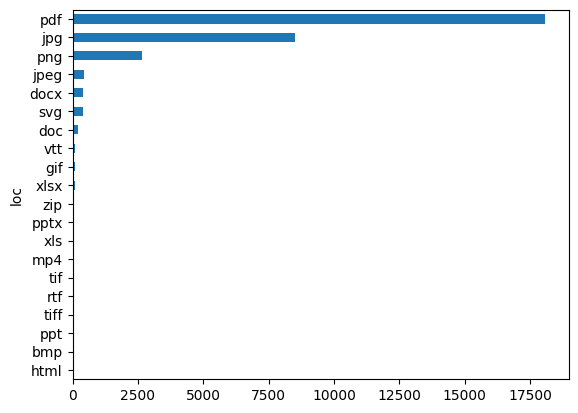

In [152]:
(
sitemap_df["loc"]
    .str.split(".")
    .str[-1]
    .str.lower()
    .value_counts()
    .head(20)
    .sort_values(ascending = True)
    .plot( kind = "barh" )
) ;